# Assignment 1 — Option Basics and Black–Scholes

Source: `Lectures/2026_fall_BME/03_bsm/presentation_03_option_basics_and_bsm_model_2026.ipynb`, cells defining `my_plotter` and `black_scholes_eur_call`.
The extensions are in `option_basics.py`; the original lecture remains unchanged.

Assumptions: European exercise, no dividends, constant continuously compounded rate $r$ and volatility $\sigma$, positive spot, strike, time and volatility. All prices are for a long option on one share. Negative rates are permitted.

## 1(a): Custom plotting (4 points)
Existing positional arguments still work. Layout settings are local to each figure. Line styles are supplied through `line_kwargs`; `show=False` permits saving/testing. Integer lists and NumPy arrays work for single or multiple curves.

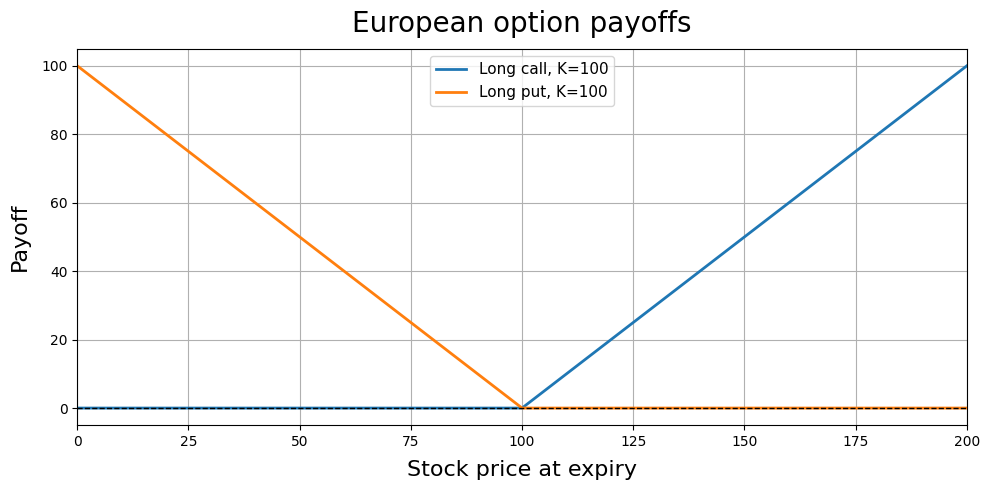

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from option_basics import my_plotter, black_scholes_eur_call, black_scholes_eur_put

spots = np.linspace(0, 200, 401)
fig, ax = my_plotter(spots, [np.maximum(spots-100, 0), np.maximum(100-spots, 0)],
    layout={'title': 'European option payoffs', 'x_label': 'Stock price at expiry',
            'y_label': 'Payoff', 'figsize': (10, 5), 'grid': True,
            'xlim': (0, 200), 'legend_fontsize': 11, 'titlepad': 12, 'labelpad': 8},
    names=['Long call, K=100', 'Long put, K=100'],
    line_kwargs={'linewidth': 2}, show=False)
plt.show()

## 1(b): Call price and Greeks (3 points)

$$d_1=\frac{\log(S_0/K)+(r+\sigma^2/2)T}{\sigma\sqrt T},\qquad d_2=d_1-\sigma\sqrt T,$$
$$C=S_0N(d_1)-Ke^{-rT}N(d_2).$$

With $\phi$ the standard normal density:

- Delta $=N(d_1)$: sensitivity to spot.
- Gamma $=\phi(d_1)/(S_0\sigma\sqrt T)$: curvature with respect to spot.
- Vega $=S_0\phi(d_1)\sqrt T$: sensitivity to volatility.
- Theta $=-S_0\phi(d_1)\sigma/(2\sqrt T)-rKe^{-rT}N(d_2)$: time decay.
- Rho $=KT e^{-rT}N(d_2)$: sensitivity to the rate.

Vega and rho are per unit change; divide by 100 for a one percentage point move. Theta is per calendar year passing: $-\partial C/\partial T$. Scalar strikes return a one-element array; strike lists return one value per strike. `return_greeks=True` returns a dictionary instead of the default price array.

The lecture's accidental dependence on global `K_vec` is corrected to use the supplied `K`.

In [2]:
parameters = dict(r=0.05, T=1.0, S0=100.0, sigma=0.2, K=100.0)
result = black_scholes_eur_call(**parameters, return_greeks=True)
for name, value in result.items():
    print(f'{name:>5}: {value[0]:.10f}')

price: 10.4505835722
delta: 0.6368306512
gamma: 0.0187620173
 vega: 37.5240346917
theta: -6.4140275464
  rho: 53.2324815454


## 1(c): European put (3 points)

$$P=Ke^{-rT}N(-d_2)-S_0N(-d_1).$$

The put uses the same inputs and validation as the call. It is calculated directly, without deriving it from parity.

Put price: 5.5735260223


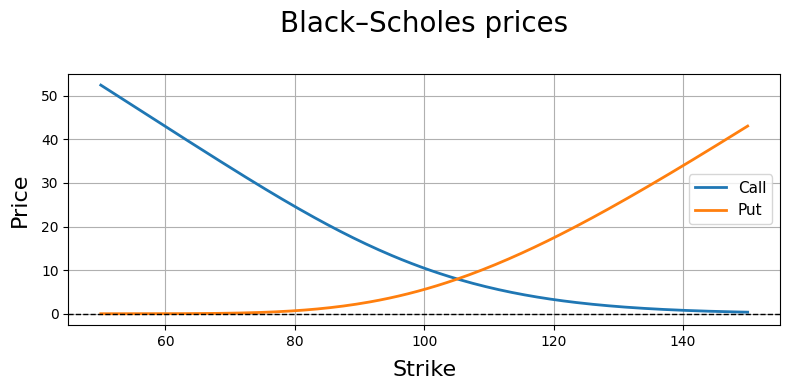

In [3]:
print(f"Put price: {black_scholes_eur_put(**parameters)[0]:.10f}")
strikes = np.linspace(50, 150, 201)
args = dict(r=.05, T=1., S0=100., sigma=.2, K=strikes)
fig, ax = my_plotter(strikes,
    [black_scholes_eur_call(**args), black_scholes_eur_put(**args)],
    layout={'title': 'Black–Scholes prices', 'x_label': 'Strike', 'y_label': 'Price',
            'grid': True, 'legend_fontsize': 11, 'labelpad': 8},
    names=['Call', 'Put'], line_kwargs={'linewidth': 2}, show=False)
plt.show()

## 1(d): Numerical put–call parity (5 points)

$$C-P=S_0-Ke^{-rT}.$$

At expiry, a long call and short put pay $S_T-K$. Buying the stock and borrowing the discounted strike produces the same payoff. Their initial prices must therefore agree under the model's assumptions.

We compare both sides for 180 contracts: five strikes, four maturities, three rates (including a negative rate), and three volatilities. We also plot both sides and their residual over strikes. The tolerance is $10^{-12}$ in price units; floating point calculations need not give an exactly zero residual.

Contracts checked: 180
Maximum absolute parity residual: 2.487e-14


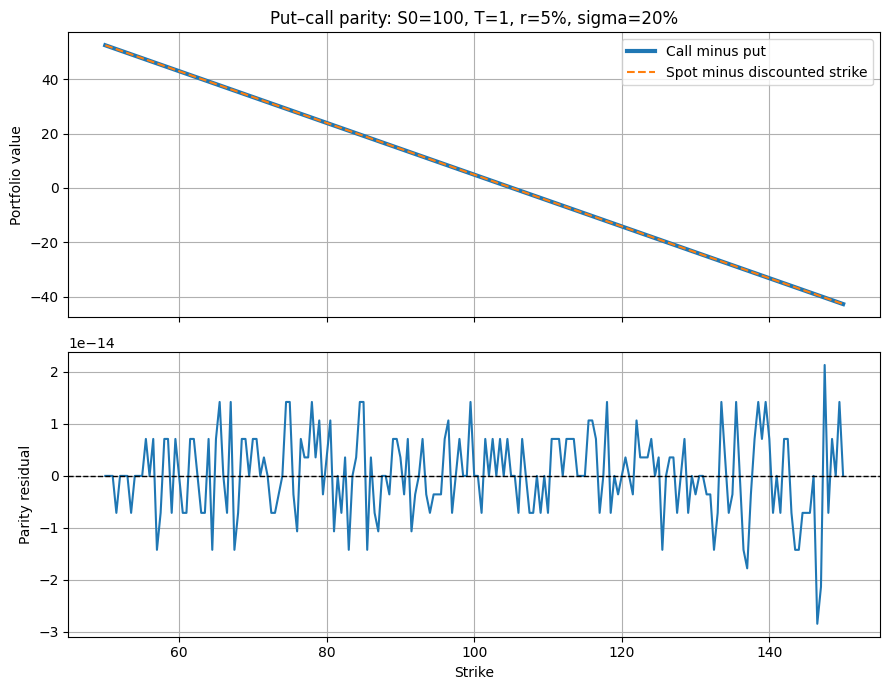

In [4]:
from itertools import product
errors = []
for rate, expiry, vol in product([-.02, 0., .05], [.01, .5, 1., 5.], [.1, .3, .8]):
    ks = np.array([50., 80., 100., 120., 160.])
    c = black_scholes_eur_call(rate, expiry, 100., vol, ks)
    p = black_scholes_eur_put(rate, expiry, 100., vol, ks)
    error = c - p - (100. - ks*np.exp(-rate*expiry))
    np.testing.assert_allclose(error, 0, atol=1e-12, rtol=0)
    errors.extend(error)
print(f'Contracts checked: {len(errors)}')
print(f'Maximum absolute parity residual: {np.max(np.abs(errors)):.3e}')

lhs = black_scholes_eur_call(**args) - black_scholes_eur_put(**args)
rhs = args['S0'] - strikes*np.exp(-args['r']*args['T'])
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
axes[0].plot(strikes, lhs, label='Call minus put', linewidth=3)
axes[0].plot(strikes, rhs, '--', label='Spot minus discounted strike')
axes[0].set_ylabel('Portfolio value')
axes[0].set_title('Put–call parity: S0=100, T=1, r=5%, sigma=20%')
axes[0].legend()
axes[1].plot(strikes, lhs-rhs)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel('Strike')
axes[1].set_ylabel('Parity residual')
for ax in axes:
    ax.grid(True)
fig.tight_layout()
plt.show()